# Project 2: News Article Clustering System
**MCA III Semester (Session 2026-2027) - COER University, Roorkee | Lab Sheet-07**

**Problem:** A news website has hundreds of articles and wants to group similar
articles automatically (sports with sports, business with business, and so on)
without anybody reading and labelling them.

**Idea:** computers need numbers, so we turn every article into a vector of numbers
with **TF-IDF**, and then cluster these vectors with **K-Means** and
**Hierarchical Clustering**.

**Workflow:** load -> clean text -> TF-IDF -> reduce dimensions -> choose the number
of clusters -> K-Means and Hierarchical -> top words of each cluster -> visualize ->
evaluate and compare -> save -> assign new articles.

## Step 1: Imports and settings

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    homogeneity_completeness_v_measure,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.preprocessing import Normalizer

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
    if BASE_DIR.name == "notebooks":
        BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))
from text_utils import clean_text  # noqa: E402  (our own small helper file)

DATA_PATH = BASE_DIR / "datasets" / "news_articles.csv"
MODEL_DIR = BASE_DIR / "models"
OUT_DIR = BASE_DIR / "outputs"
MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 42
SVD_COMPONENTS = 50
CHOSEN_K = None        # leave None to use the best K found in Step 7, or type your own number


def save_and_show(file_name):
    """Save the current figure into the outputs folder and display it."""
    plt.savefig(OUT_DIR / file_name, dpi=120, bbox_inches="tight")
    plt.show()


def internal_scores(data, labels):
    """Scores that need only the data and the clusters (no true categories)."""
    return {"Silhouette": silhouette_score(data, labels),
            "Davies-Bouldin": davies_bouldin_score(data, labels),
            "Calinski-Harabasz": calinski_harabasz_score(data, labels)}

## Step 2: Load the dataset

In [2]:
try:
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
    raw_df = pd.read_csv(DATA_PATH)
except (FileNotFoundError, pd.errors.ParserError) as err:
    print("Error while loading dataset:", err)
    raise

print("Shape:", raw_df.shape)
print(raw_df[["headline", "category"]].head())
print("\nExample article:\n", raw_df.loc[0, "text"])

Shape: (420, 4)
                                            headline    category
0             Hospital warns about rise in flu cases      Health
1                   Startup announces cloud platform  Technology
2  Cybersecurity update released for millions of ...  Technology
3      New smartphone launched with faster processor  Technology
4            The head coach wins big in league match      Sports

Example article:
 Voters will go to the polls next month and the campaign by each party has already begun. Public health officials urged people to get vaccinated and to follow advice on nutrition and sleep. The trial showed that the drug improved recovery and lowered the risk of serious disease. Local residents said they were following the news closely. Experts said regular check-ups, a balanced diet and exercise can prevent many chronic illnesses. The company said the device will support faster networks and a longer battery for everyday computing. Experts said regular check-ups, a bala

## Step 3: Explore the data (EDA)
The `category` column exists in this file, but we will **not** use it to train.
It is only used at the end to check how good the clusters are.

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   article_id  420 non-null    int64
 1   headline    420 non-null    str  
 2   text        420 non-null    str  
 3   category    420 non-null    str  
dtypes: int64(1), str(3)
memory usage: 283.3 KB

Missing values:
 article_id    0
headline      0
text          0
category      0
dtype: int64

Duplicate articles: 0

Words per article:
 count    420.0
mean      98.6
std       23.5
min       48.0
25%       80.0
50%       98.5
75%      115.0
max      157.0
Name: word_count, dtype: float64


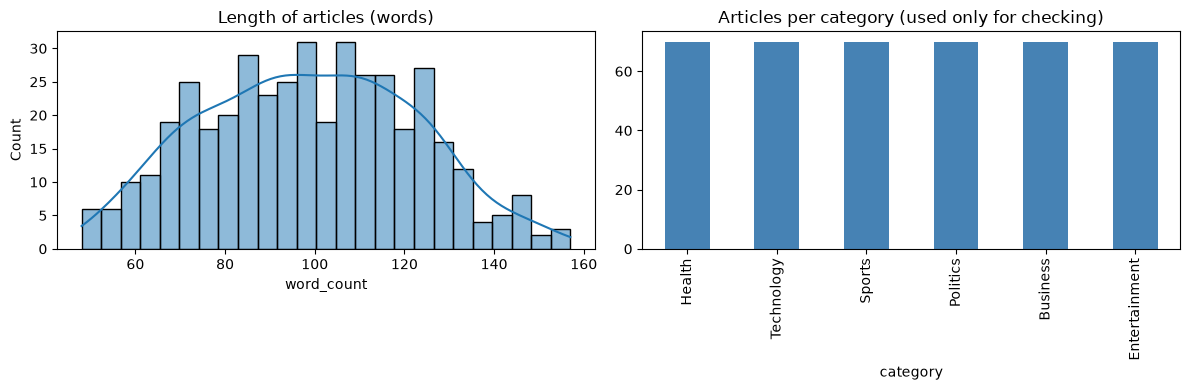

In [3]:
raw_df.info()
print("\nMissing values:\n", raw_df.isnull().sum())
print("\nDuplicate articles:", raw_df.duplicated(subset=["text"]).sum())
raw_df["word_count"] = raw_df["text"].str.split().str.len()
print("\nWords per article:\n", raw_df["word_count"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw_df["word_count"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Length of articles (words)")
raw_df["category"].value_counts().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Articles per category (used only for checking)")
plt.tight_layout()
save_and_show("p2_eda.png")

## Step 4: Clean the text
- Remove empty articles and duplicates.
- Make the text lowercase and remove digits, punctuation, stop words (like "the", "and")
  and very short words. These words carry no topic information.

Articles kept: 420

Before: Voters will go to the polls next month and the campaign by each party has already begun. Public health officials urged people to get vaccinated and to follow ad
After : voters polls month campaign party begun public health officials urged people vaccinated follow advice nutrition sleep trial showed drug improved recovery lowere


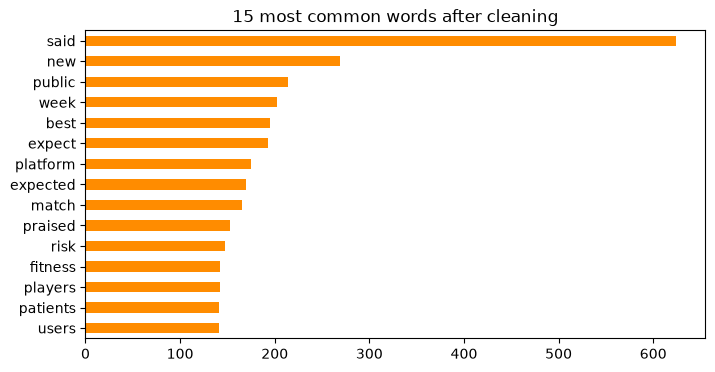

In [4]:
news_df = raw_df.dropna(subset=["text"]).drop_duplicates(subset=["text"]).reset_index(drop=True)
news_df["clean_text"] = news_df["text"].apply(clean_text)
news_df = news_df[news_df["clean_text"].str.len() > 0].reset_index(drop=True)
print("Articles kept:", len(news_df))
print("\nBefore:", news_df.loc[0, "text"][:160])
print("After :", news_df.loc[0, "clean_text"][:160])

# Most common words in the whole collection
word_counts = pd.Series(" ".join(news_df["clean_text"]).split()).value_counts().head(15)
plt.figure(figsize=(8, 4))
word_counts.sort_values().plot.barh(color="darkorange")
plt.title("15 most common words after cleaning")
save_and_show("p2_common_words.png")

## Step 5: Convert text to numbers with TF-IDF
- **TF** (term frequency): how often a word appears in an article.
- **IDF** (inverse document frequency): how rare the word is across all articles.
  Words found in almost every article (like "said") get a low weight; words that mark
  a topic (like "goal" or "vaccine") get a high weight.
- `min_df=3` ignores words used in fewer than 3 articles, `max_df=0.7` ignores words used in
  more than 70% of the articles, and `ngram_range=(1, 2)` also keeps two-word phrases.

**Feature scaling:** every TF-IDF row is already normalized to length 1, so long and short
articles are treated fairly. This is the scaling step for text.

In [5]:
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=3, max_df=0.7)
X_tfidf = tfidf.fit_transform(news_df["clean_text"])
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix shape (articles x terms):", X_tfidf.shape)
print(f"Share of zeros in the matrix: {1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]):.1%}")

first_row = X_tfidf[0].toarray().ravel()
top_ids = first_row.argsort()[::-1][:8]
print("\nHighest TF-IDF words in the first article:")
for term_id in top_ids:
    print(f"  {terms[term_id]:30s} {first_row[term_id]:.3f}")

TF-IDF matrix shape (articles x terms): (420, 1391)
Share of zeros in the matrix: 93.7%

Highest TF-IDF words in the first article:
  illnesses                      0.146
  experts said                   0.146
  diet exercise                  0.146
  said regular                   0.146
  balanced diet                  0.146
  balanced                       0.146
  regular check                  0.146
  chronic illnesses              0.146


## Step 6: Reduce the dimensions (LSA)
TF-IDF has thousands of columns and most values are zero, which makes distances less
meaningful. **TruncatedSVD** (also called LSA) squeezes the matrix into 50 columns that keep
the main topics. We then normalize the rows again. This is the standard recipe for clustering text.

In [6]:
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=RANDOM_STATE)
normalizer = Normalizer(copy=False)
X_reduced = normalizer.fit_transform(svd.fit_transform(X_tfidf))
print("Shape after SVD:", X_reduced.shape)
print(f"Information kept by {SVD_COMPONENTS} components: {svd.explained_variance_ratio_.sum():.1%}")

Shape after SVD: (420, 50)
Information kept by 50 components: 80.9%


## Step 7: Find the best number of clusters (K)
Same idea as in the customer project: elbow (inertia), silhouette (higher is better),
Davies-Bouldin (lower is better), Calinski-Harabasz (higher is better).

    Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz
K                                                         
2   348.493       0.060           3.771             25.691
3   327.329       0.080           3.251             27.124
4   307.042       0.100           2.719             28.393
5   287.015       0.123           2.526             29.966
6   267.799       0.146           2.136             31.572
7   260.312       0.143           2.162             28.981
8   254.527       0.134           2.247             26.682
9   247.203       0.130           2.247             25.502
10  242.481       0.124           2.376             23.941

Elbow method suggests K = 6
Best silhouette score at K = 6


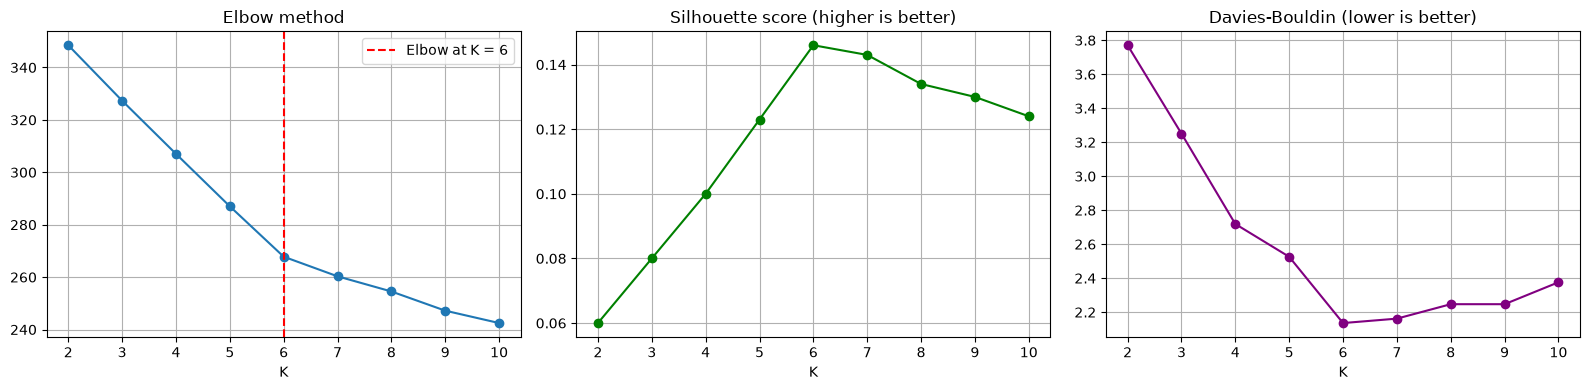


K used for the final models: 6


In [7]:
k_rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_reduced)
    k_rows.append({"K": k, "Inertia": model.inertia_, **internal_scores(X_reduced, model.labels_)})
k_table = pd.DataFrame(k_rows).set_index("K").round(3)
print(k_table)

k_values = k_table.index.to_numpy(dtype=float)
inertias = k_table["Inertia"].to_numpy()
start, end = np.array([k_values[0], inertias[0]]), np.array([k_values[-1], inertias[-1]])
direction = (end - start) / np.linalg.norm(end - start)
points = np.column_stack([k_values, inertias]) - start
elbow_k = int(k_values[np.abs(points[:, 0] * direction[1] - points[:, 1] * direction[0]).argmax()])
best_silhouette_k = int(k_table["Silhouette"].idxmax())
print(f"\nElbow method suggests K = {elbow_k}")
print(f"Best silhouette score at K = {best_silhouette_k}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(k_table.index, k_table["Inertia"], marker="o")
axes[0].axvline(elbow_k, color="red", linestyle="--", label=f"Elbow at K = {elbow_k}")
axes[0].set_title("Elbow method")
axes[0].legend()
axes[1].plot(k_table.index, k_table["Silhouette"], marker="o", color="green")
axes[1].set_title("Silhouette score (higher is better)")
axes[2].plot(k_table.index, k_table["Davies-Bouldin"], marker="o", color="purple")
axes[2].set_title("Davies-Bouldin (lower is better)")
for axis in axes:
    axis.set_xlabel("K")
    axis.grid(True)
plt.tight_layout()
save_and_show("p2_choose_k.png")

FINAL_K = CHOSEN_K if CHOSEN_K else best_silhouette_k
print("\nK used for the final models:", FINAL_K)

## Step 8: K-Means clustering and the top words of each cluster
The centre of a cluster is a point in the reduced space. We map it back to the word space
to see which words describe the cluster best.

In [8]:
kmeans = KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE).fit(X_reduced)
kmeans_labels = kmeans.labels_
news_df["kmeans_cluster"] = kmeans_labels
print("Articles in each cluster:\n", news_df["kmeans_cluster"].value_counts().sort_index())

centers_in_word_space = svd.inverse_transform(kmeans.cluster_centers_)
top_terms = {}
print("\nTop words of each cluster:")
for cluster_id in range(FINAL_K):
    best_ids = centers_in_word_space[cluster_id].argsort()[::-1][:10]
    top_terms[cluster_id] = terms[best_ids].tolist()
    print(f"  Cluster {cluster_id}: {', '.join(top_terms[cluster_id])}")

Articles in each cluster:
 kmeans_cluster
0    71
1    69
2    70
3    70
4    70
5    70
Name: count, dtype: int64

Top words of each cluster:
  Cluster 0: match, fitness, players, late, league, team, coach, points table, moved points, points
  Cluster 1: party, policy, opposition, government, begun, voters, voters polls, campaign party, polls month, month
  Cluster 2: risk, patients, treatment, health, doctor symptoms, patients talk, risk changing, symptoms medication, medication risk, changing treatment
  Cluster 3: expect, earnings, inflation, merger, stock, market, higher, rates, growth, investors
  Cluster 4: users, new, interface, software, faster, data, battery, cloud, users work, work data
  Cluster 5: best, film, reviews, critics, praised, drama, series, performances direction, critics praised, direction


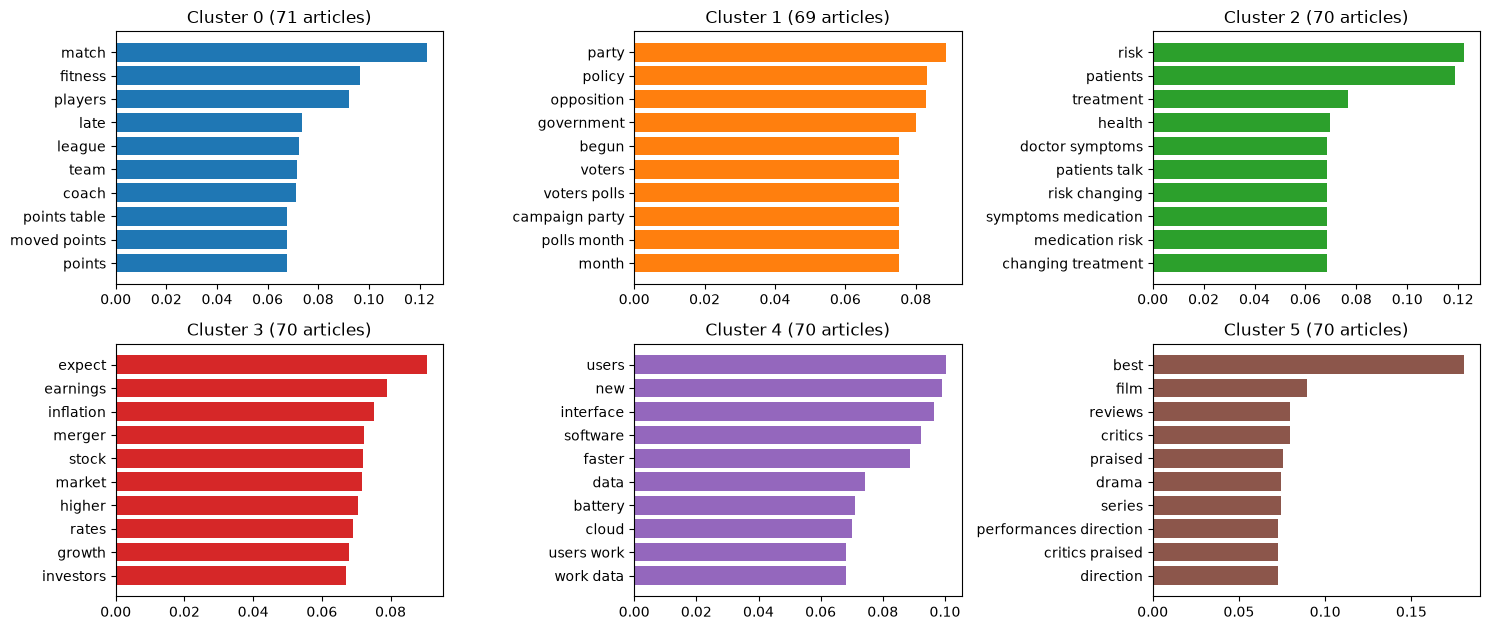

In [9]:
n_cols = min(FINAL_K, 3)
n_rows = int(np.ceil(FINAL_K / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
for cluster_id, axis in zip(range(FINAL_K), np.array(axes).ravel()):
    weights = centers_in_word_space[cluster_id][[list(terms).index(t) for t in top_terms[cluster_id]]]
    axis.barh(top_terms[cluster_id][::-1], weights[::-1], color=plt.cm.tab10(cluster_id))
    axis.set_title(f"Cluster {cluster_id} ({(kmeans_labels == cluster_id).sum()} articles)")
for axis in np.array(axes).ravel()[FINAL_K:]:
    axis.axis("off")
plt.tight_layout()
save_and_show("p2_top_words.png")

## Step 9: Hierarchical clustering
**Agglomerative** clustering starts with every article alone and keeps merging the two closest
groups. The **dendrogram** shows the merges. We use Ward linkage and also average linkage
with cosine distance (cosine is the usual distance for text).

Ward clusters: [68 70 71 69 73 69]
Cosine-average clusters: [69 69 72 70 73 67]


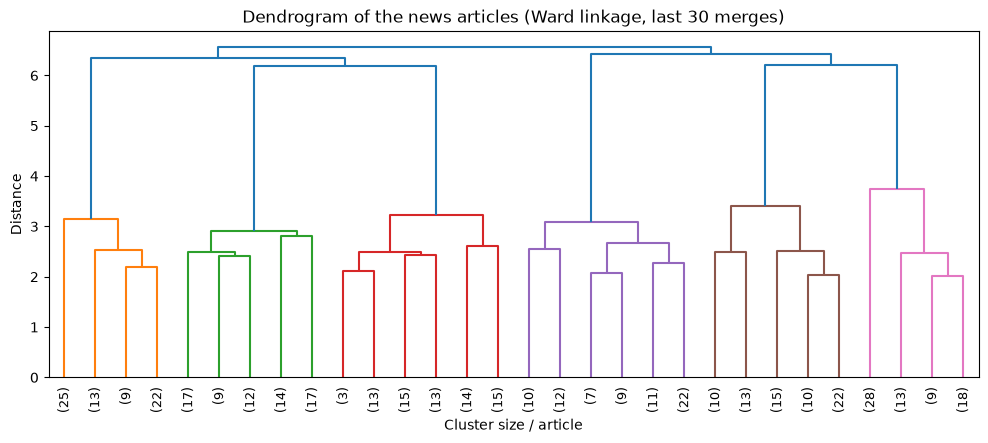

In [10]:
ward_labels = AgglomerativeClustering(n_clusters=FINAL_K, linkage="ward").fit_predict(X_reduced)
cosine_labels = AgglomerativeClustering(n_clusters=FINAL_K, metric="cosine", linkage="average").fit_predict(X_reduced)
news_df["hierarchical_cluster"] = ward_labels
print("Ward clusters:", np.bincount(ward_labels))
print("Cosine-average clusters:", np.bincount(cosine_labels))

plt.figure(figsize=(12, 4.5))
dendrogram(linkage(X_reduced, method="ward"), truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrogram of the news articles (Ward linkage, last 30 merges)")
plt.xlabel("Cluster size / article")
plt.ylabel("Distance")
save_and_show("p2_dendrogram.png")

## Step 10: Visualize the clusters in 2D
t-SNE squeezes the 50 dimensions into 2 so we can see the groups. Articles that are
close together are similar. The right picture shows the real categories, only for comparison.

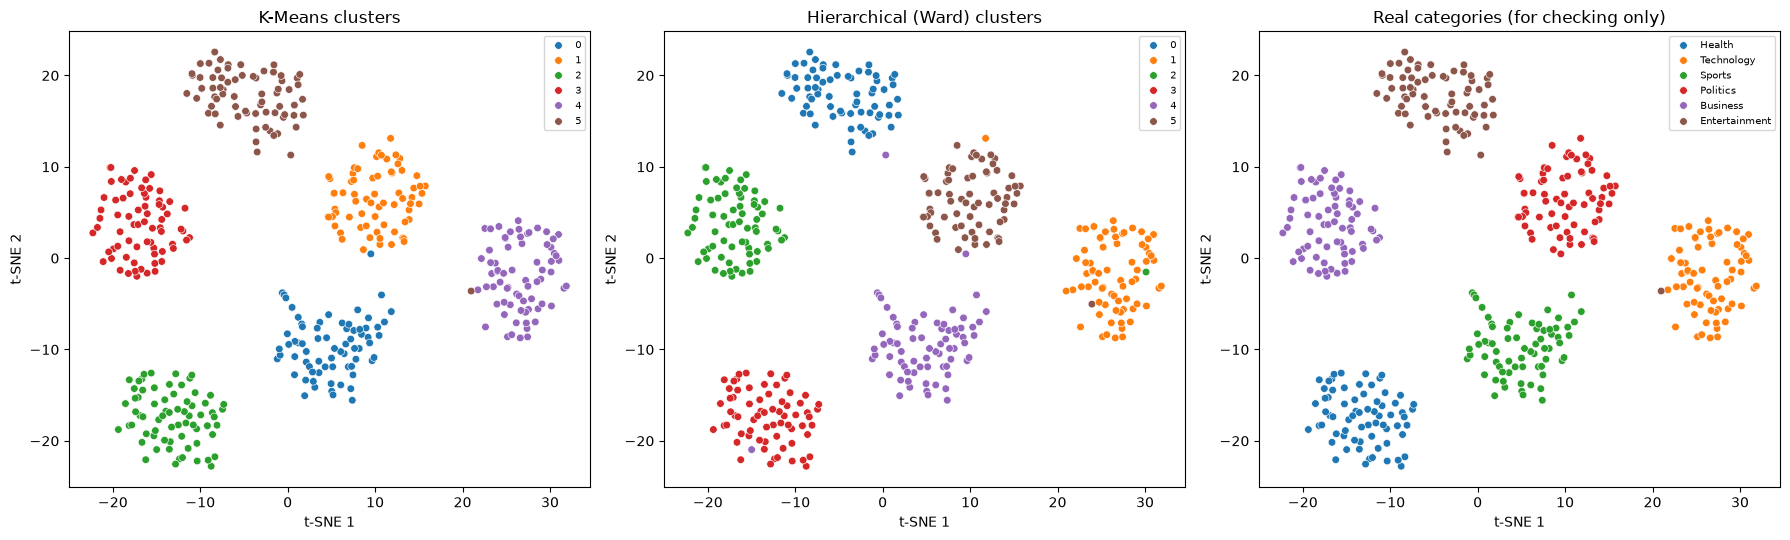

In [11]:
embedding = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X_reduced)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for axis, (title, values) in zip(axes, [("K-Means clusters", kmeans_labels),
                                        ("Hierarchical (Ward) clusters", ward_labels),
                                        ("Real categories (for checking only)", news_df["category"])]):
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=values, palette="tab10", s=30, ax=axis)
    axis.set_title(title)
    axis.set_xlabel("t-SNE 1")
    axis.set_ylabel("t-SNE 2")
    axis.legend(fontsize=7, loc="best")
plt.tight_layout()
save_and_show("p2_clusters_tsne.png")

## Step 11: Evaluate and compare the techniques
**Internal scores** (no labels needed): silhouette, Davies-Bouldin, Calinski-Harabasz.
**External scores** (compare with the real category, only possible here because the
file has categories): ARI, NMI, homogeneity, completeness, V-measure. 1 is perfect.

In [12]:
methods = {
    "K-Means (SVD space)": kmeans_labels,
    "Hierarchical (Ward)": ward_labels,
    "Hierarchical (cosine, average)": cosine_labels,
    "K-Means (raw TF-IDF)": KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tfidf),
}
rows = []
for name, method_labels in methods.items():
    homogeneity, completeness, v_measure = homogeneity_completeness_v_measure(news_df["category"], method_labels)
    rows.append({"Method": name, **internal_scores(X_reduced, method_labels),
                 "ARI": adjusted_rand_score(news_df["category"], method_labels),
                 "NMI": normalized_mutual_info_score(news_df["category"], method_labels),
                 "Homogeneity": homogeneity, "Completeness": completeness, "V-measure": v_measure})
comparison_table = pd.DataFrame(rows).set_index("Method").round(3)
print(comparison_table)
print("\nBest by silhouette:", comparison_table["Silhouette"].idxmax())
print("Best by V-measure :", comparison_table["V-measure"].idxmax())

                                Silhouette  Davies-Bouldin  Calinski-Harabasz    ARI    NMI  Homogeneity  Completeness  V-measure
Method                                                                                                                           
K-Means (SVD space)                  0.146           2.136             31.572  0.994  0.993        0.993         0.993      0.993
Hierarchical (Ward)                  0.142           2.151             30.923  0.960  0.951        0.951         0.951      0.951
Hierarchical (cosine, average)       0.143           2.170             31.067  0.949  0.944        0.943         0.944      0.944
K-Means (raw TF-IDF)                 0.146           2.136             31.572  0.994  0.993        0.993         0.993      0.993

Best by silhouette: K-Means (SVD space)
Best by V-measure : K-Means (SVD space)


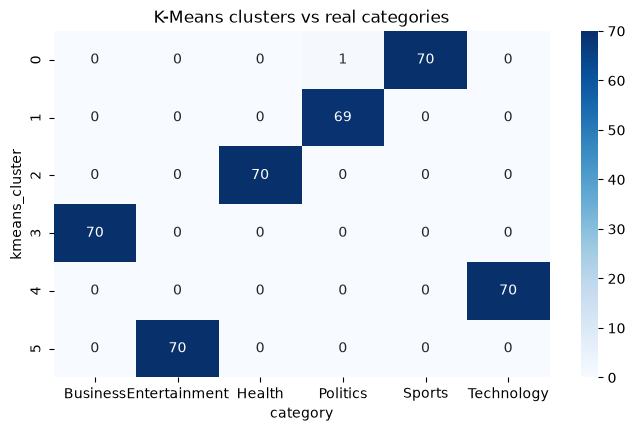

Main category of each cluster: {0: 'Sports', 1: 'Politics', 2: 'Health', 3: 'Business', 4: 'Technology', 5: 'Entertainment'}
Purity (share of articles in the main category of their cluster): 99.8%


In [13]:
# Which real categories ended up in each K-Means cluster?
crosstab = pd.crosstab(news_df["kmeans_cluster"], news_df["category"])
plt.figure(figsize=(8, 4.5))
sns.heatmap(crosstab, annot=True, fmt="d", cmap="Blues")
plt.title("K-Means clusters vs real categories")
save_and_show("p2_cluster_vs_category.png")

cluster_names = {int(cluster): str(crosstab.loc[cluster].idxmax()) for cluster in crosstab.index}
purity = crosstab.max(axis=1).sum() / crosstab.to_numpy().sum()
print("Main category of each cluster:", cluster_names)
print(f"Purity (share of articles in the main category of their cluster): {purity:.1%}")

## Step 12: Save the model and the clustered articles

In [14]:
try:
    bundle = {"tfidf": tfidf, "svd": svd, "normalizer": normalizer, "kmeans": kmeans,
              "top_terms": top_terms, "cluster_names": cluster_names}
    joblib.dump(bundle, MODEL_DIR / "news_clustering_model.joblib")
    news_df[["article_id", "headline", "category", "kmeans_cluster", "hierarchical_cluster"]].to_csv(
        OUT_DIR / "news_clustered.csv", index=False)
    print("Saved model:", MODEL_DIR / "news_clustering_model.joblib")
    print("Saved data :", OUT_DIR / "news_clustered.csv")
except OSError as err:
    print("Could not save files:", err)

Saved model: c:\Users\rajen\OneDrive\Desktop\ml lab\LAB 07\project2_news_clustering\models\news_clustering_model.joblib
Saved data : c:\Users\rajen\OneDrive\Desktop\ml lab\LAB 07\project2_news_clustering\outputs\news_clustered.csv


## Step 13: Load the saved model and assign new articles to clusters

In [15]:
bundle = joblib.load(MODEL_DIR / "news_clustering_model.joblib")
new_articles = [
    "The striker scored twice as the team won the championship match in front of a packed stadium.",
    "The central bank cut interest rates and the stock market rose as investors expected stronger profits.",
    "Researchers launched a new artificial intelligence tool and a cloud platform for software developers.",
    "Doctors recommend a vaccination and regular exercise to lower the risk of heart disease.",
]
vectors = bundle["tfidf"].transform([clean_text(article) for article in new_articles])
reduced = bundle["normalizer"].transform(bundle["svd"].transform(vectors))
new_clusters = bundle["kmeans"].predict(reduced)
for article, cluster in zip(new_articles, new_clusters):
    print(f"Article : {article[:70]}...")
    print(f"  -> Cluster {cluster} (mostly {bundle['cluster_names'][int(cluster)]}) | "
          f"top words: {', '.join(bundle['top_terms'][int(cluster)][:5])}\n")

Article : The striker scored twice as the team won the championship match in fro...
  -> Cluster 0 (mostly Sports) | top words: match, fitness, players, late, league

Article : The central bank cut interest rates and the stock market rose as inves...
  -> Cluster 3 (mostly Business) | top words: expect, earnings, inflation, merger, stock

Article : Researchers launched a new artificial intelligence tool and a cloud pl...
  -> Cluster 4 (mostly Technology) | top words: users, new, interface, software, faster

Article : Doctors recommend a vaccination and regular exercise to lower the risk...
  -> Cluster 2 (mostly Health) | top words: risk, patients, treatment, health, doctor symptoms



## Conclusion
News articles were cleaned, turned into TF-IDF vectors, reduced with SVD and clustered
with K-Means and Hierarchical Clustering. The number of clusters was chosen with the elbow
method and the silhouette score. The top words describe each cluster, the techniques were
compared with internal and external scores, and the model can assign new articles to clusters.